In [3]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import joblib

pd.set_option('display.max_columns', None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
sales = pd.read_csv(
    "../data/processed/feature_engineered_sales.csv"
)

sales["InvoiceDate"] = pd.to_datetime(
    sales["InvoiceDate"],
    errors="coerce"
)

print("Shape:", sales.shape)

sales.head()

Shape: (779425, 48)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,Revenue,Year,Month,MonthName,Quarter,Day,DayName,DayOfWeek,WeekOfYear,Date,Hour,IsWeekend,IsWeekday,YearMonth,WeekStart,MonthStart,InvoiceQuantity,InvoiceRevenue,InvoiceItems,InvoiceCustomers,CustomerRevenue,CustomerQuantity,CustomerOrders,CustomerProducts,CustomerCountries,FirstPurchase,LastPurchase,AverageOrderValue,CustomerLifetimeDays,OrdersPerLifetimeDay,ProductQuantity,ProductRevenue,ProductOrders,ProductCustomers,ProductFirstSale,ProductLastSale,ProductAveragePrice,CustomerRevenueShare,ProductRevenueShare
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,2525,18618.75,432,309,2009-12-01 07:45:00,2011-12-07 14:34:00,7.750915,0.00014,0.001072
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,2234,13198.10,229,132,2009-12-01 07:45:00,2011-01-11 13:54:00,6.426087,0.00014,0.000760
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,2948,17384.80,313,174,2009-12-01 07:45:00,2010-09-16 09:07:00,6.398089,0.00014,0.001001
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,6845,15088.77,319,101,2009-12-01 07:45:00,2011-12-08 12:07:00,2.454954,0.00014,0.000868
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0,2009,12,December,4,1,Tuesday,1,49,2009-12-01,7,0,1,2009-12,2009-11-30,2009-12-01,166,505.3,8,1,2433.28,944,8,50,1,2009-12-01 07:45:00,2011-07-05 12:11:00,304.16,581,0.013769,34935,40994.71,1893,689,2009-12-01 07:45:00,2011-12-08 15:31:00,1.239695,0.00014,0.002359


In [5]:
print(sales.info())

<class 'pandas.DataFrame'>
RangeIndex: 779425 entries, 0 to 779424
Data columns (total 48 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   Invoice               779425 non-null  int64         
 1   StockCode             779425 non-null  str           
 2   Description           779425 non-null  str           
 3   Quantity              779425 non-null  int64         
 4   InvoiceDate           779425 non-null  datetime64[us]
 5   Price                 779425 non-null  float64       
 6   Customer ID           779425 non-null  float64       
 7   Country               779425 non-null  str           
 8   IsCancelled           779425 non-null  bool          
 9   Revenue               779425 non-null  float64       
 10  Year                  779425 non-null  int64         
 11  Month                 779425 non-null  int64         
 12  MonthName             779425 non-null  str           
 13  Quarter   

In [7]:
sales[
    [
        "Customer ID",
        "Invoice",
        "InvoiceDate",
        "Quantity",
        "Revenue"
    ]
].head()

,Customer ID,Invoice,InvoiceDate,Quantity,Revenue
0,13085.0,489434,2009-12-01 07:45:00,12,83.4
1,13085.0,489434,2009-12-01 07:45:00,12,81.0
2,13085.0,489434,2009-12-01 07:45:00,12,81.0
3,13085.0,489434,2009-12-01 07:45:00,48,100.8
4,13085.0,489434,2009-12-01 07:45:00,24,30.0


In [9]:
## Determine the analysis date

# RFM requires a reference date.a
# Latest transaction date + 1 day

analysis_date = (
    sales["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

print("Latest transaction:", sales["InvoiceDate"].max())
print("Analysis date:", analysis_date)

Latest transaction: 2011-12-09 12:50:00
Analysis date: 2011-12-10 12:50:00


In [ ]:
# Calculate RFM
# Recency

# Number of days since the customer's last purchase.

# Frequency

# Number of unique invoices/orders.

# Monetary

# Total revenue generated by the customer.

In [11]:
rfm = (
    sales.groupby("Customer ID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (analysis_date - x.max()).days
        ),
        Frequency=(
            "Invoice",
            "nunique"
        ),
        Monetary=(
            "Revenue",
            "sum"
        )
    )
    .reset_index()
)

rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40


In [12]:
rfm.describe()

,Customer ID,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000,5878.000000
mean,15315.313542,201.331916,6.289384,2955.904095
std,1715.572666,209.338707,13.009406,14440.852688
min,12346.000000,1.000000,1.000000,2.950000
25%,13833.250000,26.000000,1.000000,342.280000
50%,15314.500000,96.000000,3.000000,867.740000
75%,16797.750000,380.000000,7.000000,2248.305000
max,18287.000000,739.000000,398.000000,580987.040000


In [13]:
## Check for invalid RFM values

print("Missing values:")
print(rfm.isna().sum())

print("\nRecency <= 0:", (rfm["Recency"] <= 0).sum())
print("Frequency <= 0:", (rfm["Frequency"] <= 0).sum())
print("Monetary <= 0:", (rfm["Monetary"] <= 0).sum())

Missing values:
Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64

Recency <= 0: 0
Frequency <= 0: 0
Monetary <= 0: 0


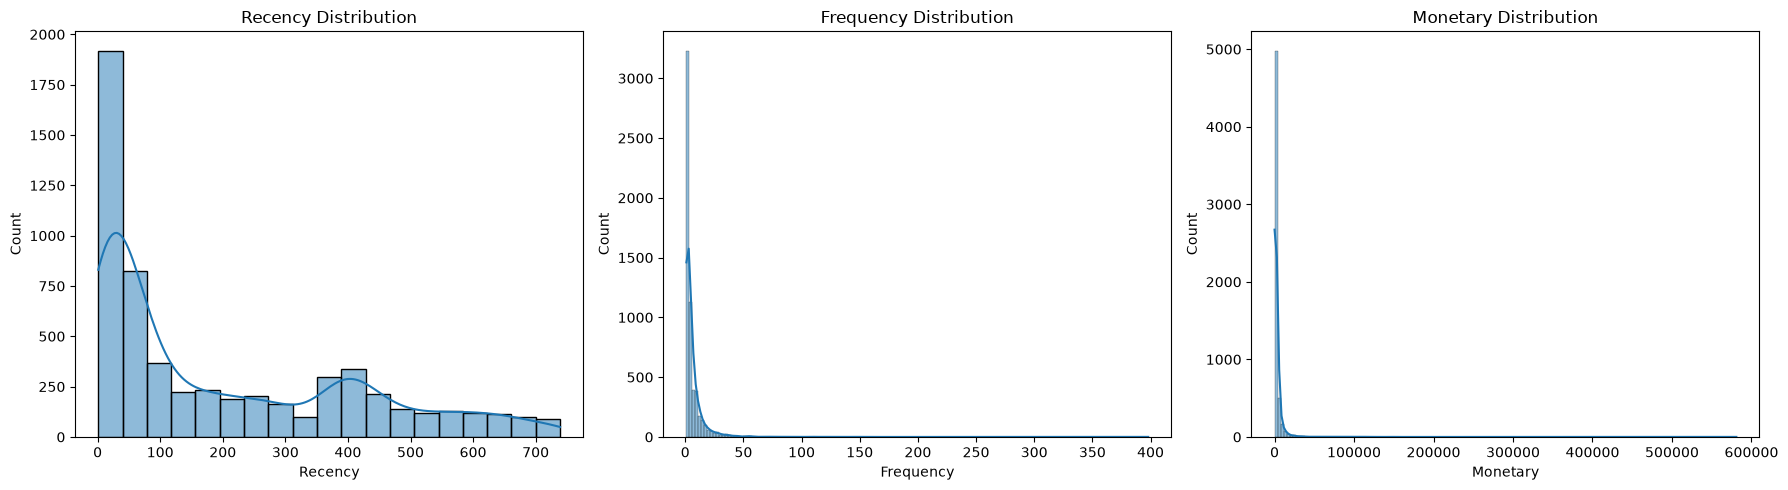

In [14]:
# Examine RFM distributions

# Customer spending and purchase frequency are usually highly skewed.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    rfm["Recency"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Recency Distribution")

sns.histplot(
    rfm["Frequency"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Frequency Distribution")

sns.histplot(
    rfm["Monetary"],
    kde=True,
    ax=axes[2]
)

axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()

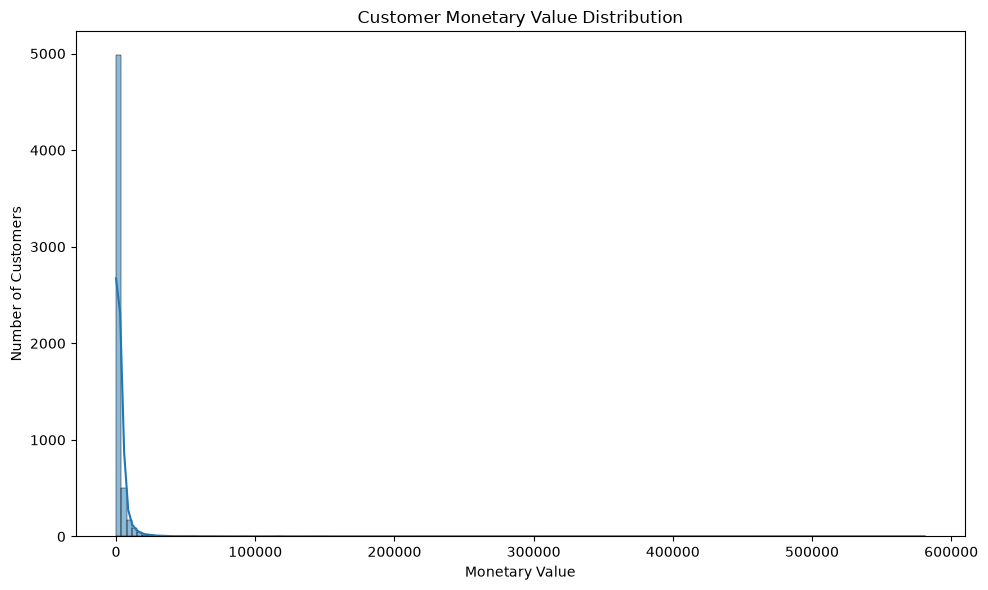

In [15]:
# Save the RFM distribution


figure_dir = "../reports/figures"

os.makedirs(
    figure_dir,
    exist_ok=True
)

plt.figure(figsize=(10, 6))

sns.histplot(
    rfm["Monetary"],
    kde=True
)

plt.title("Customer Monetary Value Distribution")
plt.xlabel("Monetary Value")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/rfm_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ##  Create RFM scores

# We will convert each RFM variable into a score from 1 to 5.

# For:

# Recency

# Lower is better, so:

# recent customer → higher score

# For:

# Frequency

# Higher is better.

# For:

# Monetary

# Higher is better.

# We can use quantiles.

In [16]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

In [19]:
## Check scores

rfm[
    [
        "Customer ID",
        "Recency",
        "Frequency",
        "Monetary",
        "R_Score",
        "F_Score",
        "M_Score"
    ]
].head(20)

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346.0,326,12,77556.46,2,5,5
1,12347.0,2,8,4921.53,5,4,5
2,12348.0,75,5,2019.40,3,4,4
3,12349.0,19,4,4428.69,5,3,5
4,12350.0,310,1,334.40,2,1,2
5,12351.0,375,1,300.93,2,1,2
6,12352.0,36,10,2849.84,4,5,4
7,12353.0,204,2,406.76,2,2,2
8,12354.0,232,1,1079.40,2,1,3
9,12355.0,214,2,947.61,2,2,3


In [20]:
## Create the overall RFM score

# We'll calculate the average of the three scores.

rfm["RFM_Score"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

rfm["RFM_Average"] = (
    rfm["RFM_Score"] / 3
)

rfm.head()



,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Average
0,12346.0,326,12,77556.46,2,5,5,12,4.000000
1,12347.0,2,8,4921.53,5,4,5,14,4.666667
2,12348.0,75,5,2019.40,3,4,4,11,3.666667
3,12349.0,19,4,4428.69,5,3,5,13,4.333333
4,12350.0,310,1,334.40,2,1,2,5,1.666667


In [21]:
# ## Create customer segments

# Now we translate the RFM values into business-friendly segments.

# We will use transparent rules rather than claiming that these labels are objectively determined by the data.  




In [22]:
def assign_rfm_segment(row):
    
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]
    
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    
    elif r >= 4 and f >= 3 and m >= 3:
        return "Loyal Customers"
    
    elif r >= 4 and f <= 2:
        return "New / Promising"
    
    elif r <= 2 and f >= 4 and m >= 4:
        return "At Risk High Value"
    
    elif r <= 2 and f >= 3:
        return "At Risk"
    
    elif r <= 2 and f <= 2 and m <= 2:
        return "Lost Customers"
    
    elif m >= 4:
        return "High Value"
    
    else:
        return "Potential Customers"

In [23]:
rfm["Segment"] = rfm.apply(
    assign_rfm_segment,
    axis=1
)

rfm.head(20)

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Average,Segment
0,12346.0,326,12,77556.46,2,5,5,12,4.000000,At Risk High Value
1,12347.0,2,8,4921.53,5,4,5,14,4.666667,Champions
2,12348.0,75,5,2019.40,3,4,4,11,3.666667,High Value
3,12349.0,19,4,4428.69,5,3,5,13,4.333333,Loyal Customers
4,12350.0,310,1,334.40,2,1,2,5,1.666667,Lost Customers
5,12351.0,375,1,300.93,2,1,2,5,1.666667,Lost Customers
6,12352.0,36,10,2849.84,4,5,4,13,4.333333,Champions
7,12353.0,204,2,406.76,2,2,2,6,2.000000,Lost Customers
8,12354.0,232,1,1079.40,2,1,3,6,2.000000,Potential Customers
9,12355.0,214,2,947.61,2,2,3,7,2.333333,Potential Customers


In [24]:
 ## Count customers by segment

segment_counts = (
    rfm["Segment"]
    .value_counts()
)

segment_counts

Segment
Champions              1289
Lost Customers         1282
Potential Customers     993
At Risk                 602
High Value              588
Loyal Customers         460
New / Promising         441
At Risk High Value      223
Name: count, dtype: int64

In [25]:
## Calculate segment percentages

segment_percentage = (
    rfm["Segment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

segment_percentage

Segment
Champions              21.93
Lost Customers         21.81
Potential Customers    16.89
At Risk                10.24
High Value             10.00
Loyal Customers         7.83
New / Promising         7.50
At Risk High Value      3.79
Name: proportion, dtype: float64

In [27]:
segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("Customer ID", "nunique"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean"),
        TotalRevenue=("Monetary", "sum")
    )
    .reset_index()
)

segment_summary

,Segment,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalRevenue
0,At Risk,602,378.730897,3.446844,1010.402658,6.082624e+05
1,At Risk High Value,223,342.295964,8.977578,4404.135345,9.821222e+05
2,Champions,1289,19.719162,17.146625,9169.609678,1.181963e+07
3,High Value,588,137.006803,7.292517,3564.628158,2.096001e+06
4,Lost Customers,1282,466.888456,1.185647,252.918293,3.242413e+05
5,Loyal Customers,460,24.100000,4.089130,1254.171524,5.769189e+05
6,New / Promising,441,27.965986,1.460317,888.522132,3.918383e+05
7,Potential Customers,993,152.218530,2.474320,579.852006,5.757930e+05


In [28]:
## Sort the segment summary

segment_summary = segment_summary.sort_values(
    "TotalRevenue",
    ascending=False
)

segment_summary

,Segment,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalRevenue
2,Champions,1289,19.719162,17.146625,9169.609678,1.181963e+07
3,High Value,588,137.006803,7.292517,3564.628158,2.096001e+06
1,At Risk High Value,223,342.295964,8.977578,4404.135345,9.821222e+05
0,At Risk,602,378.730897,3.446844,1010.402658,6.082624e+05
5,Loyal Customers,460,24.100000,4.089130,1254.171524,5.769189e+05
7,Potential Customers,993,152.218530,2.474320,579.852006,5.757930e+05
6,New / Promising,441,27.965986,1.460317,888.522132,3.918383e+05
4,Lost Customers,1282,466.888456,1.185647,252.918293,3.242413e+05


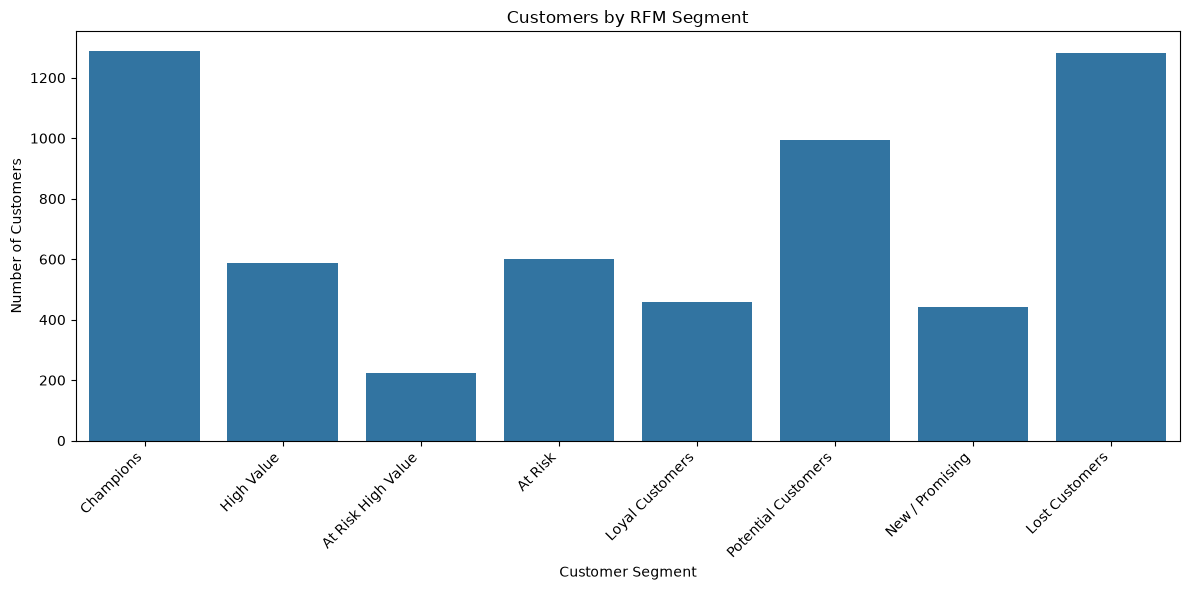

In [29]:
## Visualize customer segments
plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Customers"
)

plt.title("Customers by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

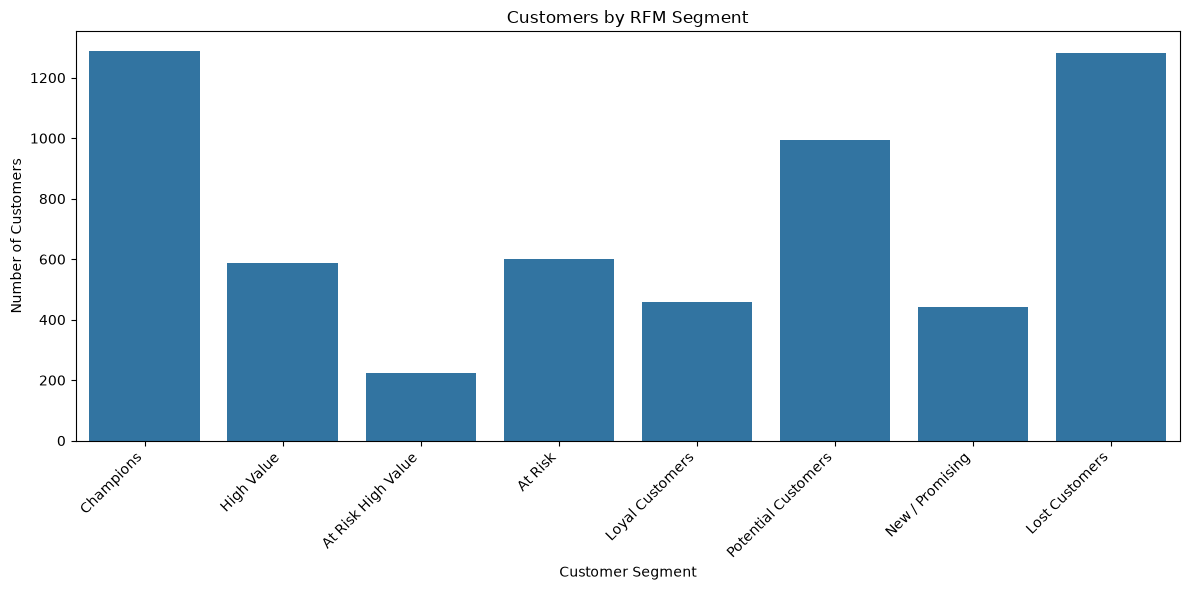

In [30]:
## Save segment chart

plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Customers"
)

plt.title("Customers by RFM Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




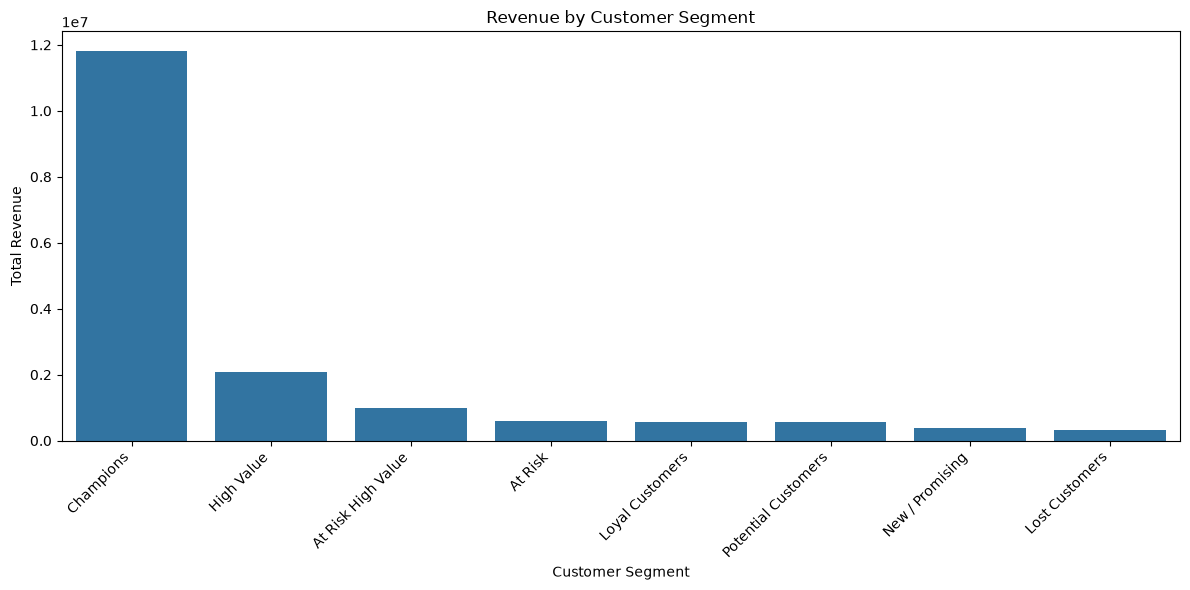

In [31]:
# Revenue by customer segment

# This is often more useful than just customer count.


plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_summary,
    x="Segment",
    y="TotalRevenue"
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

In [32]:
## Prepare data for K-Means

# Now we'll build an unsupervised ML model.

# Features:

# Recency
# Frequency
# Monetary


rfm_features = rfm[
    [
        "Recency",
        "Frequency",
        "Monetary"
    ]
].copy()

rfm_features.head()

,Recency,Frequency,Monetary
0,326,12,77556.46
1,2,8,4921.53
2,75,5,2019.40
3,19,4,4428.69
4,310,1,334.40


In [33]:
# Handle skewed RFM values
rfm_log = np.log1p(
    rfm_features
)

rfm_log.describe()

,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,4.454132,1.549588,6.816979
std,1.559404,0.809447,1.385486
min,0.693147,0.693147,1.373716
25%,3.295837,0.693147,5.838546
50%,4.574711,1.386294,6.767044
75%,5.942799,2.079442,7.718377
max,6.606650,5.988961,13.272485


In [34]:
## Standardize RFM features
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_log
)

print(
    "Scaled shape:",
    rfm_scaled.shape
)

Scaled shape: (5878, 3)


In [35]:
# Find a suitable number of clusters

# We'll test several cluster counts. 

inertia = []
silhouette_scores = []

cluster_range = range(2, 9)

for k in cluster_range:
    
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = model.fit_predict(
        rfm_scaled
    )
    
    inertia.append(
        model.inertia_
    )
    
    silhouette_scores.append(
        silhouette_score(
            rfm_scaled,
            labels
        )
    )

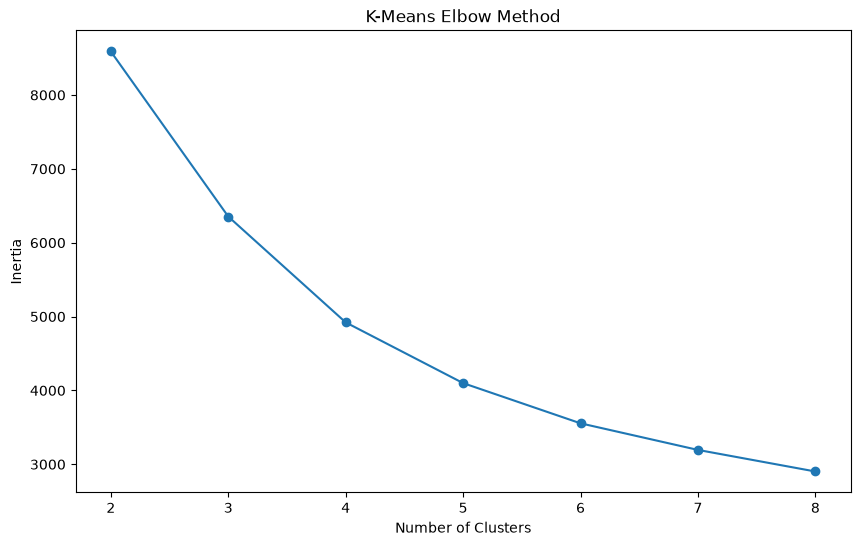

In [37]:
## Elbow method

plt.figure(figsize=(10, 6))

plt.plot(
    list(cluster_range),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")

plt.xticks(
    list(cluster_range)
)

plt.show()


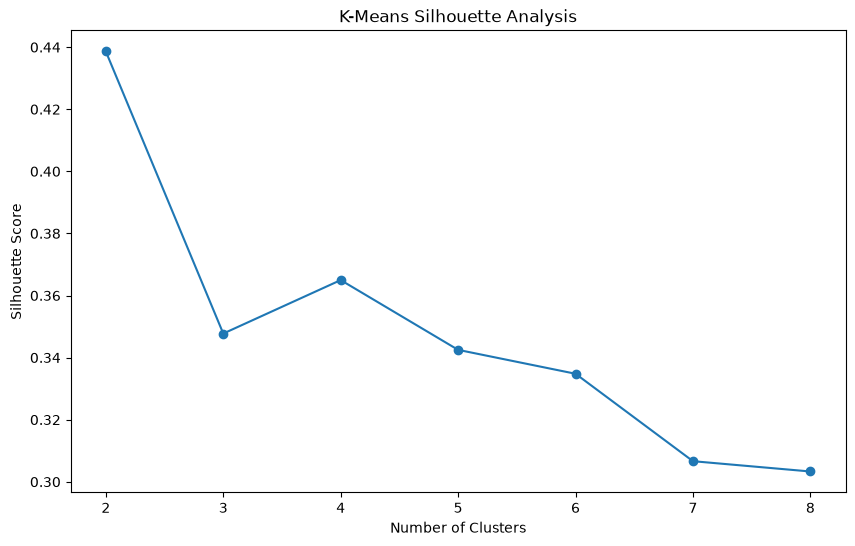

In [38]:
## Silhouette analysis

plt.figure(figsize=(10, 6))

plt.plot(
    list(cluster_range),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Analysis")

plt.xticks(
    list(cluster_range)
)

plt.show()

In [39]:
## Train K-Means

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(
    rfm_scaled
)

rfm["Cluster"].value_counts().sort_index()

Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64

In [42]:
## Analyze clusters

cluster_summary = (
    rfm.groupby("Cluster")
    .agg(
        Customers=("Customer ID", "nunique"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean")
    )
    .reset_index()
)

cluster_summary


,Cluster,Customers,AvgRecency,AvgFrequency,AvgMonetary
0,0,1973,394.946275,1.377598,317.081501
1,1,1250,28.304800,3.053600,857.491434
2,2,1196,27.711538,19.275920,10731.162991
3,3,1459,230.072653,5.058259,1948.503933


In [43]:
cluster_summary

,Cluster,Customers,AvgRecency,AvgFrequency,AvgMonetary
0,0,1973,394.946275,1.377598,317.081501
1,1,1250,28.304800,3.053600,857.491434
2,2,1196,27.711538,19.275920,10731.162991
3,3,1459,230.072653,5.058259,1948.503933


In [44]:
cluster_labels = {
    0: "Cluster 0",
    1: "Cluster 1",
    2: "Cluster 2",
    3: "Cluster 3"
}

In [45]:
rfm["ML_Segment"] = rfm["Cluster"].map(
    cluster_labels
)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Average,Segment,Cluster,ML_Segment
0,12346.0,326,12,77556.46,2,5,5,12,4.000000,At Risk High Value,2,Cluster 2
1,12347.0,2,8,4921.53,5,4,5,14,4.666667,Champions,2,Cluster 2
2,12348.0,75,5,2019.40,3,4,4,11,3.666667,High Value,3,Cluster 3
3,12349.0,19,4,4428.69,5,3,5,13,4.333333,Loyal Customers,1,Cluster 1
4,12350.0,310,1,334.40,2,1,2,5,1.666667,Lost Customers,0,Cluster 0


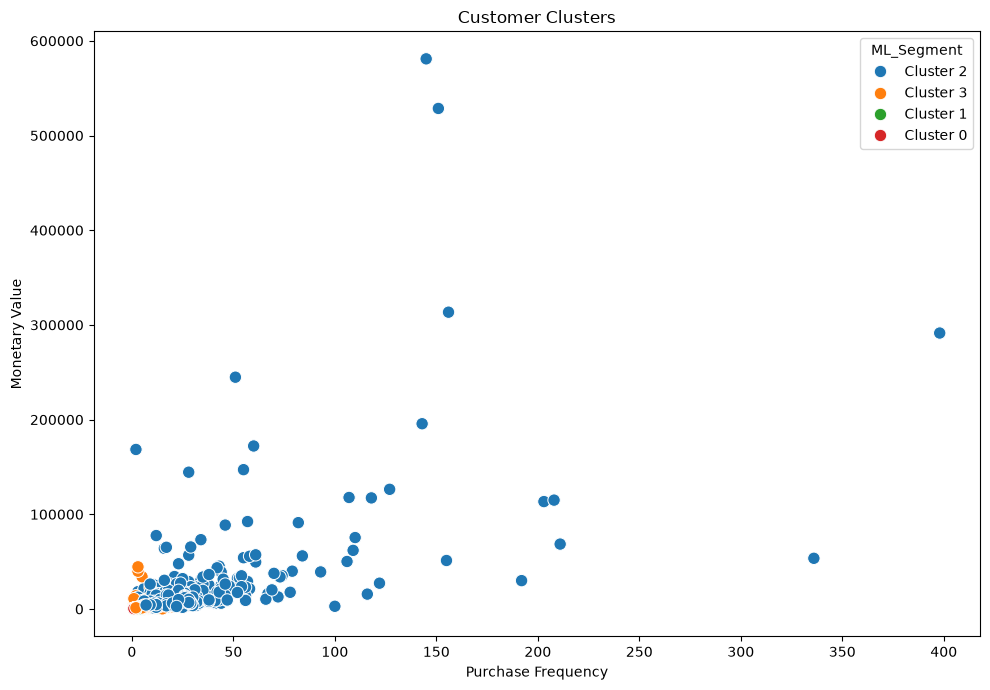

In [46]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="ML_Segment",
    palette="tab10",
    s=80
)

plt.title("Customer Clusters")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary Value")

plt.tight_layout()
plt.show()

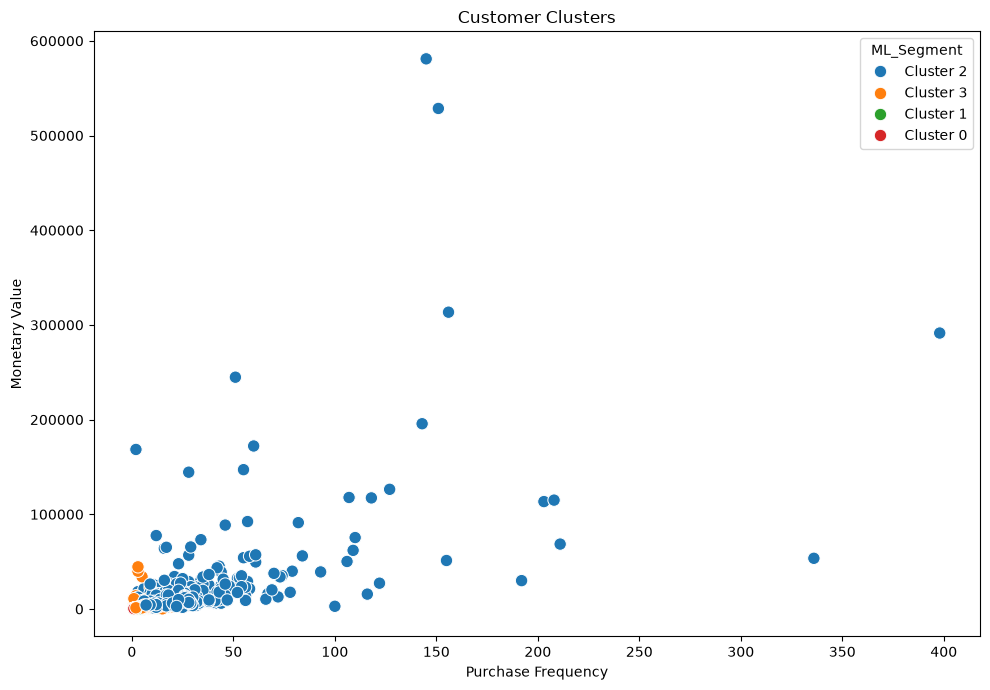

In [48]:
## Save cluster visualization

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="ML_Segment",
    palette="tab10",
    s=80
)

plt.title("Customer Clusters")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary Value")

plt.tight_layout()

plt.savefig(
    f"{figure_dir}/customer_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
#   Create final RFM dataset

# Let's add the useful customer features from Step 4.


customer_features = pd.read_csv(
    "../data/processed/customer_features.csv"
)

customer_features["FirstPurchase"] = pd.to_datetime(
    customer_features["FirstPurchase"]
)

customer_features["LastPurchase"] = pd.to_datetime(
    customer_features["LastPurchase"]
)

customer_features.head()

,Customer ID,CustomerRevenue,CustomerQuantity,CustomerOrders,CustomerProducts,CustomerCountries,FirstPurchase,LastPurchase,AverageOrderValue,CustomerLifetimeDays,OrdersPerLifetimeDay
0,12346.0,77556.46,74285,12,27,1,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,400,0.030000
1,12347.0,4921.53,2967,8,126,1,2010-10-31 14:20:00,2011-12-07 15:52:00,615.191250,402,0.019900
2,12348.0,2019.40,2714,5,25,1,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,362,0.013812
3,12349.0,4428.69,1624,4,138,1,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,570,0.007018
4,12350.0,334.40,197,1,17,1,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,0,0.000000


In [50]:
rfm_final = rfm.merge(
    customer_features,
    on="Customer ID",
    how="left"
)

print("Final RFM shape:", rfm_final.shape)

Final RFM shape: (5878, 22)


In [52]:
rfm_final[
    [
        "Customer ID",
        "Recency",
        "Frequency",
        "Monetary",
        "RFM_Score",
        "Segment",
        "Cluster",
        "ML_Segment"
    ]
].head(20)

,Customer ID,Recency,Frequency,Monetary,RFM_Score,Segment,Cluster,ML_Segment
0,12346.0,326,12,77556.46,12,At Risk High Value,2,Cluster 2
1,12347.0,2,8,4921.53,14,Champions,2,Cluster 2
2,12348.0,75,5,2019.40,11,High Value,3,Cluster 3
3,12349.0,19,4,4428.69,13,Loyal Customers,1,Cluster 1
4,12350.0,310,1,334.40,5,Lost Customers,0,Cluster 0
5,12351.0,375,1,300.93,5,Lost Customers,0,Cluster 0
6,12352.0,36,10,2849.84,13,Champions,2,Cluster 2
7,12353.0,204,2,406.76,6,Lost Customers,0,Cluster 0
8,12354.0,232,1,1079.40,6,Potential Customers,0,Cluster 0
9,12355.0,214,2,947.61,7,Potential Customers,3,Cluster 3


In [53]:
processed_dir = "../data/processed"

os.makedirs(
    processed_dir,
    exist_ok=True
)

rfm_final.to_csv(
    f"{processed_dir}/rfm_customer_segments.csv",
    index=False
)

print(
    "Saved:",
    f"{processed_dir}/rfm_customer_segments.csv"
)

Saved: ../data/processed/rfm_customer_segments.csv


In [55]:
## Save cluster data

cluster_data = rfm_final[
    [
        "Customer ID",
        "Recency",
        "Frequency",
        "Monetary",
        "R_Score",
        "F_Score",
        "M_Score",
        "RFM_Score",
        "RFM_Average",
        "Segment",
        "Cluster",
        "ML_Segment"
    ]
].copy()

cluster_data.to_csv(
    f"{processed_dir}/customer_clusters.csv",
    index=False
)

print("Saved customer_clusters.csv")

Saved customer_clusters.csv


In [56]:
## Save the K-Means model

model_dir = "../models"

os.makedirs(
    model_dir,
    exist_ok=True
)

joblib.dump(
    kmeans,
    f"{model_dir}/customer_segmentation.pkl"
)

joblib.dump(
    scaler,
    f"{model_dir}/rfm_scaler.pkl"
)

print("K-Means model saved.")
print("RFM scaler saved.")

K-Means model saved.
RFM scaler saved.


In [57]:
## Save cluster summary

cluster_summary.to_csv(
    f"{processed_dir}/cluster_summary.csv",
    index=False
)

segment_summary.to_csv(
    f"{processed_dir}/rfm_segment_summary.csv",
    index=False
)

print("Summary files saved.")

Summary files saved.


In [58]:
## Final RFM validation

print("=" * 70)
print("RETAILPULSE RFM SEGMENTATION COMPLETE")
print("=" * 70)

print(
    f"Customers analyzed: "
    f"{rfm_final['Customer ID'].nunique():,}"
)

print(
    f"Average Recency: "
    f"{rfm_final['Recency'].mean():.2f} days"
)

print(
    f"Average Frequency: "
    f"{rfm_final['Frequency'].mean():.2f} orders"
)

print(
    f"Total Customer Revenue: "
    f"{rfm_final['Monetary'].sum():,.2f}"
)

print(
    f"RFM Segments: "
    f"{rfm_final['Segment'].nunique()}"
)

print(
    f"ML Clusters: "
    f"{rfm_final['Cluster'].nunique()}"
)

print("=" * 70)



RETAILPULSE RFM SEGMENTATION COMPLETE
Customers analyzed: 5,878
Average Recency: 201.33 days
Average Frequency: 6.29 orders
Total Customer Revenue: 17,374,804.27
RFM Segments: 8
ML Clusters: 4
